# 05 — Advanced Models: gradient boosting (LightGBM and XGBoost)

**Week 7:** try gradient boosting, do light hyperparameter tuning (tree depth, learning rate, number of trees), and report test metrics.

Same setup as Weeks 4–6 so results compare directly: Week 3 preprocessor, target `log(ClosePrice)`, train on the 15 months before the test month, test on April 2026. Feature set **C** from Week 6 (Week 3 inputs + school district layer). Hyperparameters are chosen on the three validation cutoffs (Jan, Feb, Mar 2026; each cutoff refits its own thresholds and preprocessor on its own window). April is scored once, at the end.

**To beat (Random Forest, set C, Week 6):** April MdAPE 7.53%, R² 0.906; validation mean MdAPE 7.48%.

Regenerate with `notebooks/_build_05_advanced_models.py`, then run the notebook (about 85 minutes on 2 CPU cores; most of it is the tuning grid).

## 1. Setup

In [1]:
import sys, json, time, platform, itertools
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import joblib, sklearn, lightgbm, xgboost
from lightgbm import LGBMRegressor
from xgboost import XGBRegressor
from sklearn.ensemble import RandomForestRegressor

ROOT = next(p for p in [Path("."), Path("..")] if (p / "processed").exists()).resolve()
sys.path.insert(0, str(ROOT / "py"))
import preprocessing as pp
import modeling as mdl
import feature_engineering as fe

PROC, RES_DIR, MODEL_DIR = ROOT / "processed", ROOT / "results", ROOT / "models"
FIG_DIR = ROOT / "figures" / "05_advanced_models"
for d in (FIG_DIR, RES_DIR, MODEL_DIR): d.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 40); pd.set_option("display.width", 160)
BLUE, ORANGE, GREEN, GREY, PURPLE = "#2a78d6", "#eb6834", "#2e9e6a", "#8a8984", "#7a5cc7"
sns.set_theme(style="whitegrid", rc={"axes.edgecolor": "#d0cfca", "grid.color": "#ecebe7",
                                     "axes.titleweight": "bold", "figure.dpi": 110})
def save(fig, name): fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight", dpi=130)

np.random.seed(pp.SEED)
cfg = json.loads((PROC / "preprocessing_config.json").read_text())
X_MONTHS, TEST_MONTH = cfg["train_window_months"], cfg["test_month"]
VAL_MONTHS = ["2026-01", "2026-02", "2026-03"]
run6 = json.loads((RES_DIR / "week6_run_info.json").read_text())
RF_PARAMS = run6["hyperparameters"]["random_forest"]
print(f"python {platform.python_version()} | scikit-learn {sklearn.__version__} | lightgbm {lightgbm.__version__} | "
      f"xgboost {xgboost.__version__} | X = {X_MONTHS} | test = {TEST_MONTH}")

python 3.13.18 | scikit-learn 1.7.2 | lightgbm 4.7.0 | xgboost 3.4.1 | X = 15 | test = 2026-04


## 2. Load data (Week 6 features from the cached school district join)

In [2]:
clean = fe.add_home_features(mdl.load_clean(PROC / "sold_sfr_clean.csv"))
clean = fe.add_school_features(clean, pd.read_csv(PROC / "school_district_join.csv", dtype={"ListingKey": str}))
train, test = clean[clean.split == "train"], clean[clean.split == "test"]
y = test.ClosePrice.to_numpy()

SETS = {"A. Old (Week 5)": fe.feature_set(), "C. + school district": fe.feature_set(school=True),
        "D. New (all)": fe.feature_set(home=True, school=True)}
FS = SETS["C. + school district"]
print(f"train {len(train):,} | test {len(test):,} | feature set C: {sum(len(v) for v in FS.values())} inputs")

train 155,216 | test 12,175 | feature set C: 32 inputs


## 3. Why gradient boosting

A Random Forest grows deep trees independently and averages them. Gradient boosting grows many **small** trees one after another, each one fitted to the errors the previous trees still make, with each tree's contribution shrunk by the *learning rate*. The three settings that matter most:

| Setting | LightGBM | XGBoost | Effect |
|---|---|---|---|
| Tree size | `num_leaves` (leaf-wise growth) | `max_depth` (level-wise growth) | larger trees capture more interactions but overfit sooner |
| Learning rate | `learning_rate` | `learning_rate` | smaller = each tree corrects less; needs more trees, usually generalises better |
| Number of trees | `n_estimators` | `n_estimators` | too few underfits; too many slowly overfits |

Kept fixed (common defaults, not tuned): row subsampling 0.8 per tree, column subsampling 0.7 per tree, LightGBM `min_child_samples = 20`, XGBoost `min_child_weight = 1`.

**Tuning trick:** a boosted model with 4,000 trees also contains the models with 100, 250, … trees, so `n_estimators` is scored at several checkpoints from one fit (`mdl.staged_log_predictions`) instead of refitting.

## 4. Preprocess each cutoff once

In [3]:
t = time.time()
cuts = mdl.cutoff_matrices(clean, VAL_MONTHS + [TEST_MONTH], X_MONTHS, FS)
for m, c in cuts.items():
    print(f"{m}: train {c['train_months']} ({c['n_train']:,} rows) | test {len(c['test']):,} | {c['X_train'].shape[1]} columns")
# The April cutoff is exactly the processed train/test split used in Weeks 3-6
assert cuts[TEST_MONTH]["n_train"] == len(train) and (cuts[TEST_MONTH]["test"].ListingKey.values == test.ListingKey.values).all()
print(f"{time.time() - t:.0f} s")

2026-01: train 2024-10 to 2025-12 (160,843 rows) | test 7,333 | 99 columns
2026-02: train 2024-11 to 2026-01 (156,092 rows) | test 8,744 | 99 columns
2026-03: train 2024-12 to 2026-02 (154,330 rows) | test 11,284 | 98 columns
2026-04: train 2025-01 to 2026-03 (155,216 rows) | test 12,175 | 98 columns
4 s


## 5. LightGBM: tree size × learning rate × number of trees

Grid: `num_leaves` ∈ {31, 63, 127, 255} × `learning_rate` ∈ {0.025, 0.05, 0.1}, each scored at 10 tree counts from 100 to 4,000 on the three validation cutoffs (36 fits, 360 scored settings).

In [4]:
CHECK = [100, 250, 500, 750, 1000, 1500, 2000, 2500, 3000, 4000]
LGB_FIXED = dict(subsample=0.8, subsample_freq=1, colsample_bytree=0.7, min_child_samples=20,
                 random_state=pp.SEED, n_jobs=-1, verbose=-1)
def mdape(y_true, log_pred): return np.median(np.abs(np.exp(log_pred) - y_true) / y_true) * 100

rows, t0 = [], time.time()
for leaves, lr in itertools.product([31, 63, 127, 255], [0.025, 0.05, 0.1]):
    t = time.time()
    for m in VAL_MONTHS:
        c = cuts[m]
        mod = LGBMRegressor(n_estimators=max(CHECK), learning_rate=lr, num_leaves=leaves, **LGB_FIXED).fit(c["X_train"], c["y_train"])
        for k, lp in mdl.staged_log_predictions(mod, c["X_test"], CHECK).items():
            rows.append({"num_leaves": leaves, "learning_rate": lr, "n_estimators": k, "month": m,
                         "MdAPE": mdape(c["test"].ClosePrice.to_numpy(), lp)})
    best_k = pd.DataFrame(rows).query("num_leaves == @leaves and learning_rate == @lr").groupby("n_estimators").MdAPE.mean()
    print(f"leaves {leaves:3d} lr {lr:<5} best val {best_k.min():.2f}% at {best_k.idxmin():,} trees ({time.time() - t:.0f} s)")
lgb_long = pd.DataFrame(rows)
lgb_tune = (lgb_long.pivot_table(index=["num_leaves", "learning_rate", "n_estimators"], columns="month", values="MdAPE")
            .assign(val_MdAPE=lambda d: d[VAL_MONTHS].mean(axis=1)).reset_index())
print(f"LightGBM grid: {time.time() - t0:.0f} s")
lgb_tune.sort_values("val_MdAPE").head(10).round(3)

leaves  31 lr 0.025 best val 7.23% at 4,000 trees (106 s)


leaves  31 lr 0.05  best val 7.10% at 4,000 trees (132 s)


leaves  31 lr 0.1   best val 7.21% at 3,000 trees (85 s)


leaves  63 lr 0.025 best val 7.13% at 4,000 trees (127 s)


leaves  63 lr 0.05  best val 7.09% at 2,500 trees (114 s)


leaves  63 lr 0.1   best val 7.17% at 2,000 trees (109 s)


... (3 outputs left out)

leaves 255 lr 0.025 best val 7.05% at 3,000 trees (250 s)


leaves 255 lr 0.05  best val 7.15% at 750 trees (231 s)


leaves 255 lr 0.1   best val 7.31% at 750 trees (233 s)
LightGBM grid: 1883 s


month,num_leaves,learning_rate,n_estimators,2026-01,2026-02,2026-03,val_MdAPE
98,255,0.025,3000,7.108,7.203,6.844,7.051
96,255,0.025,2000,7.069,7.235,6.861,7.055
69,127,0.025,4000,7.142,7.210,6.837,7.063
68,127,0.025,3000,7.142,7.181,6.872,7.065
97,255,0.025,2500,7.135,7.214,6.856,7.068
99,255,0.025,4000,7.159,7.203,6.852,7.071
95,255,0.025,1500,7.124,7.261,6.853,7.080
67,127,0.025,2500,7.174,7.198,6.874,7.082
47,63,0.050,2500,7.092,7.313,6.855,7.087
66,127,0.025,2000,7.173,7.201,6.902,7.092


LightGBM chosen on validation: {'num_leaves': 255, 'learning_rate': 0.025, 'n_estimators': 3000} -> val MdAPE 7.05%


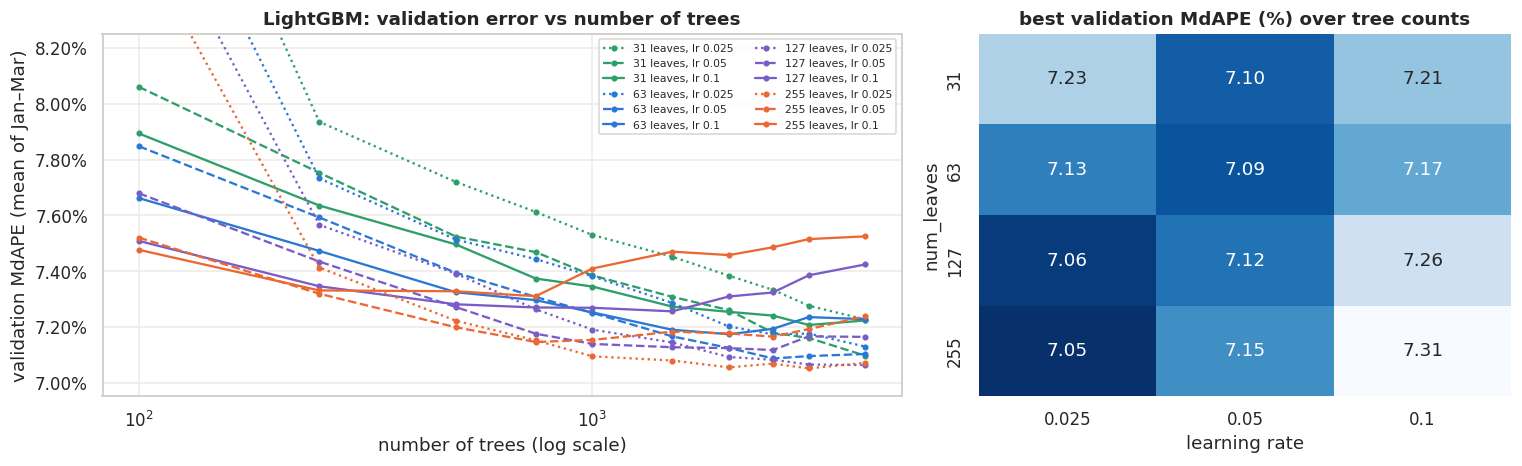

In [5]:
LGB_BEST = lgb_tune.loc[lgb_tune.val_MdAPE.idxmin()]
LGB_PARAMS = dict(num_leaves=int(LGB_BEST.num_leaves), learning_rate=float(LGB_BEST.learning_rate),
                  n_estimators=int(LGB_BEST.n_estimators))
print("LightGBM chosen on validation:", LGB_PARAMS, f"-> val MdAPE {LGB_BEST.val_MdAPE:.2f}%")

fig, ax = plt.subplots(1, 2, figsize=(14, 4.4), gridspec_kw={"width_ratios": [1.5, 1]})
pal = dict(zip([31, 63, 127, 255], [GREEN, BLUE, PURPLE, ORANGE]))
for (leaves, lr), g in lgb_tune.groupby(["num_leaves", "learning_rate"]):
    ls = {0.025: ":", 0.05: "--", 0.1: "-"}[lr]
    ax[0].plot(g.n_estimators, g.val_MdAPE, ls, color=pal[leaves], marker="o", ms=3, label=f"{leaves} leaves, lr {lr}")
ax[0].set(xscale="log", xlabel="number of trees (log scale)", ylabel="validation MdAPE (mean of Jan–Mar)",
          title="LightGBM: validation error vs number of trees")
ax[0].yaxis.set_major_formatter(mtick.PercentFormatter()); ax[0].legend(fontsize=7, ncol=2)
ax[0].set_ylim(lgb_tune.val_MdAPE.min() - 0.1, lgb_tune.val_MdAPE.min() + 1.2)
best_grid = lgb_tune.groupby(["num_leaves", "learning_rate"]).val_MdAPE.min().unstack()
sns.heatmap(best_grid, annot=True, fmt=".2f", cmap="Blues_r", cbar=False, ax=ax[1])
ax[1].set(title="best validation MdAPE (%) over tree counts", xlabel="learning rate", ylabel="num_leaves")
fig.tight_layout(); save(fig, "lgbm_tuning"); plt.show()

## 6. XGBoost: depth × learning rate × number of trees

Grid: `max_depth` ∈ {6, 8, 10} × `learning_rate` ∈ {0.05, 0.1}, scored at tree counts from 100 to 3,000 (`tree_method="hist"`).

In [6]:
CHECK_X = [c for c in CHECK if c <= 3000]
XGB_FIXED = dict(subsample=0.8, colsample_bytree=0.7, min_child_weight=1, tree_method="hist",
                 random_state=pp.SEED, n_jobs=-1)
rows, t0 = [], time.time()
for depth, lr in itertools.product([6, 8, 10], [0.05, 0.1]):
    t = time.time()
    for m in VAL_MONTHS:
        c = cuts[m]
        mod = XGBRegressor(n_estimators=max(CHECK_X), learning_rate=lr, max_depth=depth, **XGB_FIXED).fit(c["X_train"], c["y_train"])
        for k, lp in mdl.staged_log_predictions(mod, c["X_test"], CHECK_X).items():
            rows.append({"max_depth": depth, "learning_rate": lr, "n_estimators": k, "month": m,
                         "MdAPE": mdape(c["test"].ClosePrice.to_numpy(), lp)})
    best_k = pd.DataFrame(rows).query("max_depth == @depth and learning_rate == @lr").groupby("n_estimators").MdAPE.mean()
    print(f"depth {depth:2d} lr {lr:<4} best val {best_k.min():.2f}% at {best_k.idxmin():,} trees ({time.time() - t:.0f} s)")
xgb_tune = (pd.DataFrame(rows).pivot_table(index=["max_depth", "learning_rate", "n_estimators"], columns="month", values="MdAPE")
            .assign(val_MdAPE=lambda d: d[VAL_MONTHS].mean(axis=1)).reset_index())
XGB_BEST = xgb_tune.loc[xgb_tune.val_MdAPE.idxmin()]
XGB_PARAMS = dict(max_depth=int(XGB_BEST.max_depth), learning_rate=float(XGB_BEST.learning_rate),
                  n_estimators=int(XGB_BEST.n_estimators))
print(f"XGBoost grid: {time.time() - t0:.0f} s | chosen on validation: {XGB_PARAMS} -> val MdAPE {XGB_BEST.val_MdAPE:.2f}%")
xgb_tune.groupby(["max_depth", "learning_rate"]).val_MdAPE.min().unstack().round(3)

depth  6 lr 0.05 best val 7.10% at 2,500 trees (96 s)


depth  6 lr 0.1  best val 7.16% at 2,000 trees (98 s)


depth  8 lr 0.05 best val 7.12% at 2,000 trees (150 s)


depth  8 lr 0.1  best val 7.14% at 750 trees (154 s)


depth 10 lr 0.05 best val 7.07% at 750 trees (287 s)


depth 10 lr 0.1  best val 7.24% at 750 trees (379 s)
XGBoost grid: 1164 s | chosen on validation: {'max_depth': 10, 'learning_rate': 0.05, 'n_estimators': 750} -> val MdAPE 7.07%


learning_rate,0.05,0.10
max_depth,,
6,7.104,7.160
8,7.120,7.145
10,7.074,7.243


## 7. Does boosting want a different feature set?

Week 6 chose set C with the Random Forest. Boosted trees can use the home-shape ratios differently, so the chosen LightGBM is re-scored on sets A and D (validation only).

In [7]:
fs_rows = []
for sname, fs in SETS.items():
    cc = cuts if sname.startswith("C.") else mdl.cutoff_matrices(clean, VAL_MONTHS, X_MONTHS, fs)
    for m in VAL_MONTHS:
        mod = LGBMRegressor(**LGB_PARAMS, **LGB_FIXED).fit(cc[m]["X_train"], cc[m]["y_train"])
        fs_rows.append({"feature_set": sname, "month": m, "MdAPE": mdape(cc[m]["test"].ClosePrice.to_numpy(), mod.predict(cc[m]["X_test"]))})
fs_tab = pd.DataFrame(fs_rows).pivot_table(index="feature_set", columns="month", values="MdAPE").assign(val_MdAPE=lambda d: d.mean(axis=1))
fs_tab["change_vs_C"] = fs_tab.val_MdAPE - fs_tab.loc["C. + school district", "val_MdAPE"]
fs_tab.round(3)

month,2026-01,2026-02,2026-03,val_MdAPE,change_vs_C
feature_set,,,,,
A. Old (Week 5),7.142,7.301,6.883,7.109,0.057
C. + school district,7.108,7.203,6.844,7.051,0.000
D. New (all),7.118,7.238,6.903,7.086,0.035


Set C is kept unless another set is better by more than the noise (it is the set Week 6 carried forward, and it keeps all models on the same inputs).

## 8. Random Forest (Week 6, set C) on the same cutoffs, and a simple blend

The Random Forest is refitted on the same four cutoffs (Week 6 hyperparameters) so its validation predictions can be blended with the boosted models. The blend is a weighted average of **log** predictions; weights (steps of 0.1, summing to 1) are chosen on the validation cutoffs.

In [8]:
t = time.time()
vpred = {m: {} for m in cuts}           # log predictions per cutoff and model
for m, c in cuts.items():
    vpred[m]["LightGBM"] = LGBMRegressor(**LGB_PARAMS, **LGB_FIXED).fit(c["X_train"], c["y_train"]).predict(c["X_test"])
    vpred[m]["XGBoost"] = XGBRegressor(**XGB_PARAMS, **XGB_FIXED).fit(c["X_train"], c["y_train"]).predict(c["X_test"])
    vpred[m]["Random Forest"] = RandomForestRegressor(n_jobs=-1, random_state=pp.SEED, **RF_PARAMS).fit(c["X_train"], c["y_train"]).predict(c["X_test"])
    print(f"{m}: " + " | ".join(f"{k} {mdape(c['test'].ClosePrice.to_numpy(), v):.2f}%" for k, v in vpred[m].items()) + f" ({time.time() - t:.0f} s)")

# Check: the Random Forest reproduces Week 6 (set C) on April
prior = pd.read_csv(RES_DIR / "model_results.csv").set_index("model")
rf_apr = mdape(y, vpred[TEST_MONTH]["Random Forest"])
assert np.isclose(rf_apr, prior.loc["Week 6: Random Forest (C. + school district)", "MdAPE"], atol=0.01), rf_apr
print(f"Random Forest C April MdAPE {rf_apr:.2f}% (Week 6 file: {prior.loc['Week 6: Random Forest (C. + school district)', 'MdAPE']:.2f}%)")

2026-01: LightGBM 7.11% | XGBoost 7.17% | Random Forest 7.57% (145 s)


2026-02: LightGBM 7.20% | XGBoost 7.13% | Random Forest 7.56% (279 s)


2026-03: LightGBM 6.84% | XGBoost 6.92% | Random Forest 7.32% (414 s)


2026-04: LightGBM 7.12% | XGBoost 7.16% | Random Forest 7.53% (548 s)
Random Forest C April MdAPE 7.53% (Week 6 file: 7.53%)


In [9]:
NAMES = ["LightGBM", "XGBoost", "Random Forest"]
grid = [w for w in itertools.product(np.round(np.arange(0, 1.01, 0.1), 1), repeat=3) if np.isclose(sum(w), 1)]
def blend(m, w): return sum(wi * vpred[m][n] for wi, n in zip(w, NAMES))
bl = pd.DataFrame([{**dict(zip(NAMES, w)), **{m: mdape(cuts[m]["test"].ClosePrice.to_numpy(), blend(m, w)) for m in VAL_MONTHS}} for w in grid])
bl["val_MdAPE"] = bl[VAL_MONTHS].mean(axis=1)
W = tuple(bl.loc[bl.val_MdAPE.idxmin(), NAMES])
print("Blend weights chosen on validation:", dict(zip(NAMES, W)))
bl.sort_values("val_MdAPE").head(8).round(3)

Blend weights chosen on validation: {'LightGBM': 0.5, 'XGBoost': 0.5, 'Random Forest': 0.0}


,LightGBM,XGBoost,Random Forest,2026-01,2026-02,2026-03,val_MdAPE
50,0.5,0.5,0.0,7.098,7.140,6.826,7.021
62,0.8,0.2,0.0,7.068,7.181,6.830,7.027
44,0.4,0.6,0.0,7.143,7.138,6.815,7.032
37,0.3,0.7,0.0,7.143,7.147,6.810,7.033
59,0.7,0.3,0.0,7.080,7.187,6.833,7.034
42,0.4,0.4,0.2,7.114,7.142,6.852,7.036
55,0.6,0.4,0.0,7.094,7.174,6.841,7.037
49,0.5,0.4,0.1,7.107,7.181,6.833,7.040


## 9. Test metrics (April 2026, scored once)

In [10]:
for m in cuts: vpred[m]["Blend"] = blend(m, W)
MODELS = ["LightGBM", "XGBoost", "Blend", "Random Forest"]
LABEL = {"LightGBM": f"Week 7: LightGBM (C)", "XGBoost": f"Week 7: XGBoost (C)",
         "Blend": "Week 7: Blend " + "/".join(f"{w:.1f}" for w in W) + " LGBM/XGB/RF (C)", "Random Forest": "Week 6: Random Forest (C. + school district)"}
bt = pd.DataFrame({mod: {m: mdape(cuts[m]["test"].ClosePrice.to_numpy(), vpred[m][mod]) for m in cuts} for mod in MODELS}).T
bt["val_MdAPE"] = bt[VAL_MONTHS].mean(axis=1)
pred = {mod: np.exp(vpred[TEST_MONTH][mod]) for mod in MODELS}
res = pd.DataFrame([{"model": mod, "val_MdAPE": bt.loc[mod, "val_MdAPE"], **mdl.full_metrics(y, pred[mod])} for mod in MODELS]).set_index("model")

show = res[["val_MdAPE", "MdAPE", "R2", "R2_log", "MAPE", "MAE", "RMSE", "within_5pct", "within_10pct", "within_20pct", "median_bias_pct"]].copy()
fmt = {"val_MdAPE": "{:.2f}%", "MdAPE": "{:.2f}%", "R2": "{:.4f}", "R2_log": "{:.4f}", "MAPE": "{:.2f}%", "MAE": "${:,.0f}",
       "RMSE": "${:,.0f}", "within_5pct": "{:.1f}%", "within_10pct": "{:.1f}%", "within_20pct": "{:.1f}%", "median_bias_pct": "{:+.2f}%"}
for c, f in fmt.items(): show[c] = show[c].map(f.format)
show.rename(columns={"val_MdAPE": "Val MdAPE", "MdAPE": "April MdAPE", "R2": "April R²", "R2_log": "R² (log)"})

,Val MdAPE,April MdAPE,April R²,R² (log),MAPE,MAE,RMSE,within_5pct,within_10pct,within_20pct,median_bias_pct
model,,,,,,,,,,,
LightGBM,7.05%,7.12%,0.9229,0.9496,10.26%,"$137,212","$265,817",37.1%,63.5%,87.5%,-0.57%
XGBoost,7.07%,7.16%,0.9188,0.9480,10.37%,"$139,359","$272,858",37.0%,63.2%,87.2%,-0.58%
Blend,7.02%,7.06%,0.9220,0.9494,10.24%,"$137,308","$267,329",37.2%,63.6%,87.5%,-0.57%
Random Forest,7.48%,7.53%,0.9063,0.9406,10.89%,"$148,440","$293,044",35.8%,61.2%,85.6%,-1.42%


**Is the gain bigger than the noise?** MdAPE on every cutoff, and the change vs the Week 6 Random Forest (negative = better). Week 4 set a noise bar of about 0.4 points.

In [11]:
delta = bt[VAL_MONTHS + [TEST_MONTH]] - bt.loc["Random Forest", VAL_MONTHS + [TEST_MONTH]]
out = pd.concat({"MdAPE": bt[VAL_MONTHS + [TEST_MONTH]], "change vs RF": delta}, axis=1).round(2)
out[("change vs RF", "all_4_better")] = (delta < 0).all(axis=1)
out[("change vs RF", "all_4_beyond_0.4")] = (delta < -0.4).all(axis=1)
out

MdAPE                         change vs RF                                                      
              2026-01 2026-02 2026-03 2026-04      2026-01 2026-02 2026-03 2026-04 all_4_better all_4_beyond_0.4
LightGBM         7.11    7.20    6.84    7.12        -0.46   -0.36   -0.48   -0.41         True            False
XGBoost          7.17    7.13    6.92    7.16        -0.40   -0.43   -0.40   -0.37         True            False
Blend            7.10    7.14    6.83    7.06        -0.47   -0.42   -0.49   -0.47         True             True
Random Forest    7.57    7.56    7.32    7.53         0.00    0.00    0.00    0.00        False            False

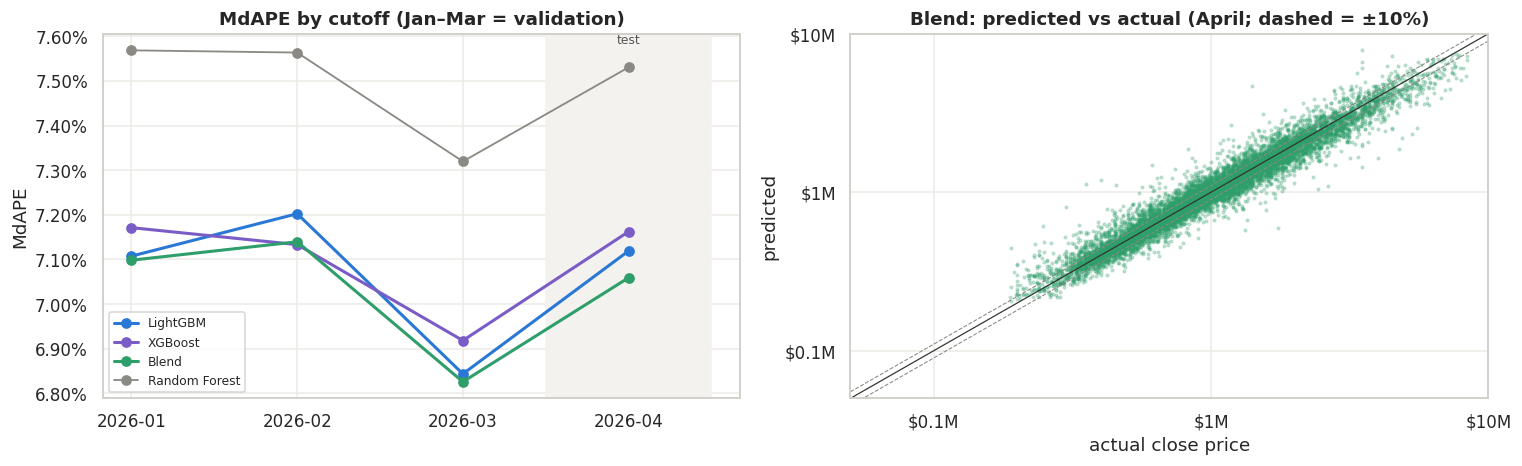

Best Week 7 model on validation: Blend


In [12]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.4))
cols = {"LightGBM": BLUE, "XGBoost": PURPLE, "Blend": GREEN, "Random Forest": GREY}
months = VAL_MONTHS + [TEST_MONTH]
for mod in MODELS:
    ax[0].plot(months, bt.loc[mod, months], marker="o", color=cols[mod], label=mod, lw=2 if mod != "Random Forest" else 1.2)
ax[0].axvspan(2.5, 3.5, color="#f3f2ee"); ax[0].text(3, ax[0].get_ylim()[1], "test", ha="center", va="top", fontsize=8, color="#555")
ax[0].set(title="MdAPE by cutoff (Jan–Mar = validation)", ylabel="MdAPE"); ax[0].yaxis.set_major_formatter(mtick.PercentFormatter()); ax[0].legend(fontsize=8)

best = res.drop("Random Forest").val_MdAPE.idxmin()
p = pred[best]
lim = [5e4, 1e7]
ax[1].scatter(y, p, s=3, alpha=0.25, color=cols[best], rasterized=True)
ax[1].plot(lim, lim, color="#333", lw=0.8)
for f_, ls in [(1.1, "--"), (0.9, "--")]: ax[1].plot(lim, np.array(lim) * f_, ls, color=GREY, lw=0.7)
ax[1].set(xscale="log", yscale="log", xlim=lim, ylim=lim, xlabel="actual close price", ylabel="predicted",
          title=f"{best}: predicted vs actual (April; dashed = ±10%)")
for a in (ax[1].xaxis, ax[1].yaxis): a.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"${v/1e6:g}M"))
fig.tight_layout(); save(fig, "backtest_and_predicted_vs_actual"); plt.show()
print("Best Week 7 model on validation:", best)

## 10. Where boosting helps: price band and county (best Week 7 model vs Week 6 Random Forest)

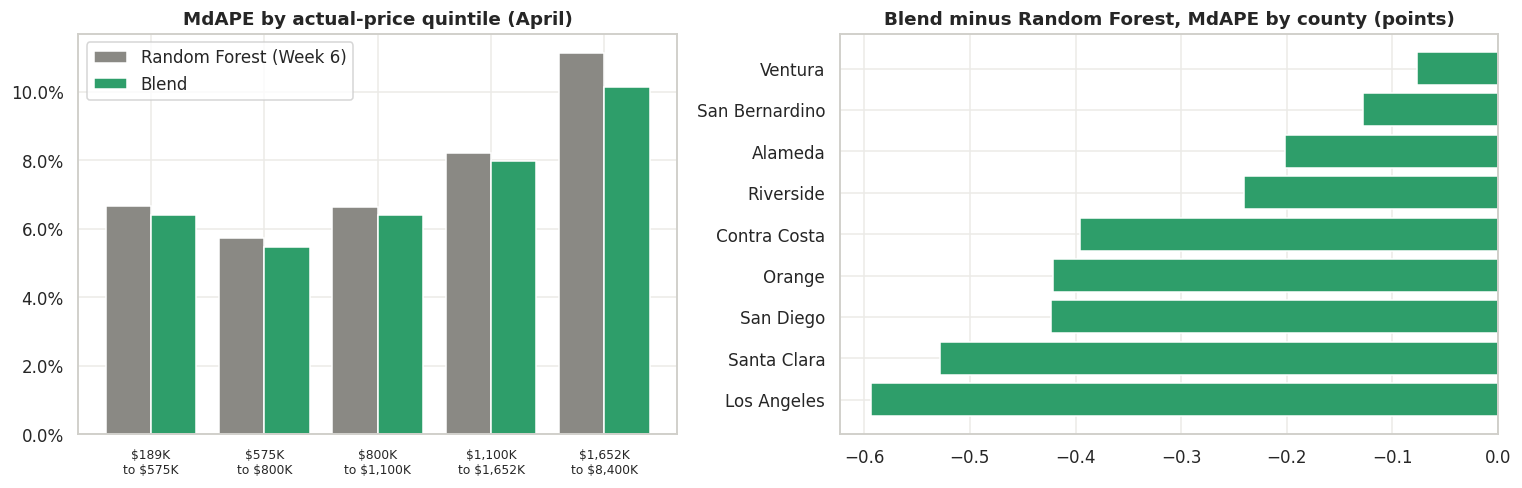

Random Forest              Blend            
                            MdAPE median_bias  MdAPE median_bias
g                                                               
Q1: $189K-$575K              6.66        1.89   6.40        1.56
Q2: $575K-$800K              5.72       -0.29   5.46       -0.00
Q3: $800K-$1,100K            6.63       -1.20   6.41       -0.31
Q4: $1,100K-$1,652K          8.22       -3.25   7.99       -1.72
Q5: $1,652K-$8,400K         11.13       -6.84  10.15       -4.48

In [13]:
bands = mdl.price_bands(y, 5)
b = pd.concat({"Random Forest": mdl.error_by_group(y, pred["Random Forest"], bands)[["MdAPE", "median_bias"]],
               best: mdl.error_by_group(y, p, bands)[["MdAPE", "median_bias"]]}, axis=1)
county = test.CountyOrParish.to_numpy()
top = pd.Series(county).value_counts().loc[lambda s: s >= 300].index
mk = np.isin(county, top)
cty = pd.concat({"Random Forest": mdl.error_by_group(y[mk], pred["Random Forest"][mk], county[mk])["MdAPE"],
                 best: mdl.error_by_group(y[mk], p[mk], county[mk])["MdAPE"]}, axis=1)
cty["change"] = cty[best] - cty["Random Forest"]
cty = cty.sort_values("change")

fig, ax = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [1, 1.1]})
xx = np.arange(len(b))
ax[0].bar(xx - 0.2, b[("Random Forest", "MdAPE")], 0.4, color=GREY, label="Random Forest (Week 6)")
ax[0].bar(xx + 0.2, b[(best, "MdAPE")], 0.4, color=cols[best], label=best)
ax[0].set_xticks(xx, [l.split(": ")[1].replace("-", "\nto ").replace("$", r"\$") for l in b.index], fontsize=8)
ax[0].set_title("MdAPE by actual-price quintile (April)"); ax[0].legend(); ax[0].yaxis.set_major_formatter(mtick.PercentFormatter())
ax[1].barh(cty.index, cty.change, color=np.where(cty.change < 0, GREEN, ORANGE))
ax[1].axvline(0, color="#555", lw=0.8); ax[1].set_title(f"{best} minus Random Forest, MdAPE by county (points)")
fig.tight_layout(); save(fig, "error_by_band_and_county"); plt.show()
b.round(2)

**What LightGBM uses** (gain importance: total log-price error reduction from splits on each input; correlated location inputs share credit, so read as descriptive).

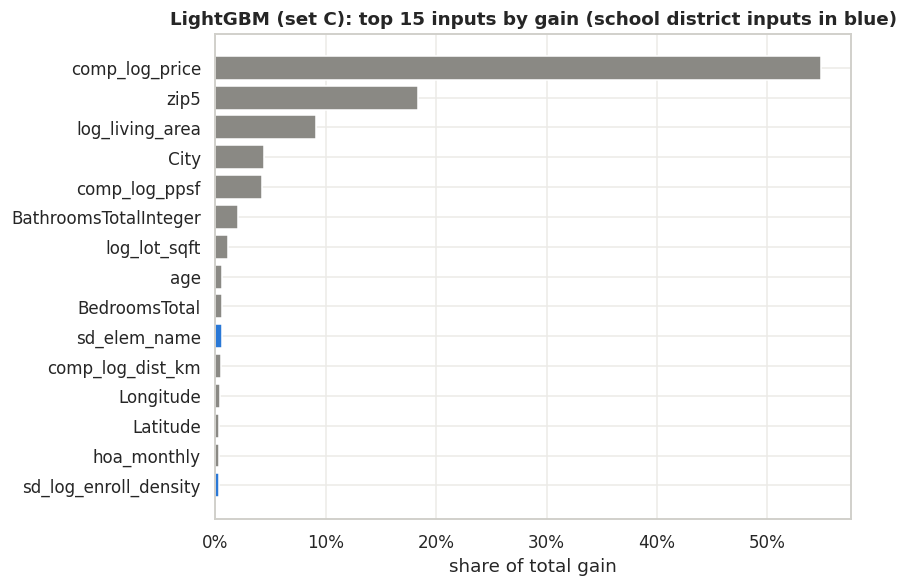

In [14]:
c = cuts[TEST_MONTH]
lgb_apr = LGBMRegressor(**LGB_PARAMS, **LGB_FIXED, importance_type="gain").fit(c["X_train"], c["y_train"])
names = pd.Series(c["feature_names"]).str.replace(r"^(num|bin|low|high)__", "", regex=True)
imp = pd.Series(lgb_apr.feature_importances_, index=names)
imp = (imp / imp.sum()).sort_values()
top15 = imp.tail(15)
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(top15.index, top15.values, color=[BLUE if n.startswith("sd_") else GREY for n in top15.index])
ax.set(title="LightGBM (set C): top 15 inputs by gain (school district inputs in blue)", xlabel="share of total gain")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
fig.tight_layout(); save(fig, "lgbm_feature_importance"); plt.show()
assert np.allclose(lgb_apr.predict(c["X_test"]), vpred[TEST_MONTH]["LightGBM"])

## 11. Save the fitted model and results

The chosen LightGBM and XGBoost are saved as full scikit-learn pipelines (preprocessor + model, fitted on the April training window), so a later app can call `predict` on raw columns. Check: the saved pipelines give the same April predictions as above.

In [15]:
saved = {}
for mod, est in [("LightGBM", LGBMRegressor(**LGB_PARAMS, **LGB_FIXED)), ("XGBoost", XGBRegressor(**XGB_PARAMS, **XGB_FIXED))]:
    pipe = mdl.fit(mdl.make_pipeline(est, features=FS), train)
    path = MODEL_DIR / f"{mod.lower()}.joblib"
    joblib.dump(pipe, path, compress=3)
    diff = np.max(np.abs(mdl.predict_price(pipe, test) / pred[mod] - 1))
    assert diff < 1e-6, (mod, diff)
    saved[mod] = str(path.relative_to(ROOT))
    print(f"{path.relative_to(ROOT)} ({path.stat().st_size / 1e6:.1f} MB); max relative difference vs above {diff:.1e}")

models/lightgbm.joblib (27.3 MB); max relative difference vs above 1.8e-15


models/xgboost.joblib (13.8 MB); max relative difference vs above 0.0e+00


In [16]:
lgb_tune.to_csv(RES_DIR / "week7_tuning_lightgbm.csv", index=False)
xgb_tune.to_csv(RES_DIR / "week7_tuning_xgboost.csv", index=False)
bl.to_csv(RES_DIR / "week7_blend_weights.csv", index=False)
fs_tab.to_csv(RES_DIR / "week7_feature_set_check.csv")
bt.to_csv(RES_DIR / "week7_backtest_mdape.csv")
res.to_csv(RES_DIR / "week7_test_metrics.csv")
test[["ListingKey", "close_month", "CountyOrParish", "ClosePrice"]].assign(
    **{f"pred_{k.lower().replace(' ', '_')}": pred[k].round(0) for k in MODELS}).to_csv(RES_DIR / "week7_test_predictions.csv", index=False)

new_rows = [{"model": LABEL[m], **{k: res.loc[m, k] for k in prior.columns if k in res.columns},
             "test_month": TEST_MONTH, "train_window_months": X_MONTHS, "train_rows": len(train),
             "validation_MdAPE_mean": res.loc[m, "val_MdAPE"]} for m in ["LightGBM", "XGBoost", "Blend"]]
outr = pd.concat([prior.reset_index()[lambda d: ~d.model.str.startswith("Week 7")], pd.DataFrame(new_rows)], ignore_index=True)
outr[prior.reset_index().columns].to_csv(RES_DIR / "model_results.csv", index=False)

(RES_DIR / "week7_run_info.json").write_text(json.dumps({
    "feature_set": "C. + school district", "features": FS,
    "lightgbm": {**LGB_PARAMS, **{k: v for k, v in LGB_FIXED.items() if k not in ("n_jobs", "verbose")}},
    "xgboost": {**XGB_PARAMS, **{k: v for k, v in XGB_FIXED.items() if k != "n_jobs"}},
    "random_forest": RF_PARAMS, "blend_weights_log_scale": dict(zip(NAMES, W)),
    "grids": {"lightgbm": {"num_leaves": [31, 63, 127, 255], "learning_rate": [0.025, 0.05, 0.1], "n_estimators": CHECK},
              "xgboost": {"max_depth": [6, 8, 10], "learning_rate": [0.05, 0.1], "n_estimators": CHECK_X}},
    "chosen_on": VAL_MONTHS, "best_week7_model_on_validation": best, "saved_models": saved,
    "seed": pp.SEED, "test_month": TEST_MONTH,
    "versions": {"python": platform.python_version(), "scikit-learn": sklearn.__version__,
                 "lightgbm": lightgbm.__version__, "xgboost": xgboost.__version__}}, indent=2))
pd.read_csv(RES_DIR / "model_results.csv")[["model", "MdAPE", "R2", "MAPE", "validation_MdAPE_mean"]].round(4)

,model,MdAPE,R2,MAPE,validation_MdAPE_mean
0,Reference: comp median price (no model),12.0283,0.7066,17.5404,NaN
1,Reference: comp price/sq ft x living area (no ...,12.7087,0.8606,16.5783,NaN
2,Baseline: Linear Regression,8.6252,0.8886,12.0194,8.7466
3,Week 5: Decision Tree,8.9818,0.8857,12.6446,9.0836
4,Week 5: Random Forest,7.5792,0.9060,10.9543,7.5141
5,Week 6: Linear Regression (D. New (all)),8.5106,0.8887,11.9258,8.6508
6,Week 6: Decision Tree (C. + school district),9.0606,0.8846,12.6717,9.0747
7,Week 6: Random Forest (C. + school district),7.5306,0.9063,10.8921,7.4840
8,Week 7: LightGBM (C),7.1192,0.9229,10.2571,7.0512
9,Week 7: XGBoost (C),7.1625,0.9188,10.3695,7.0744


## 12. Summary

In [17]:
rf = res.loc["Random Forest"]
for m in ["LightGBM", "XGBoost", "Blend"]:
    r = res.loc[m]
    print(f"{m:9s} val {r.val_MdAPE:.2f}% | April MdAPE {r.MdAPE:.2f}% ({r.MdAPE - rf.MdAPE:+.2f} vs RF) | R2 {r.R2:.4f} | MAPE {r.MAPE:.2f}% | within 10% {r.within_10pct:.1f}%")
print(f"RF (W6)   val {rf.val_MdAPE:.2f}% | April MdAPE {rf.MdAPE:.2f}% | R2 {rf.R2:.4f} | MAPE {rf.MAPE:.2f}%")

LightGBM  val 7.05% | April MdAPE 7.12% (-0.41 vs RF) | R2 0.9229 | MAPE 10.26% | within 10% 63.5%
XGBoost   val 7.07% | April MdAPE 7.16% (-0.37 vs RF) | R2 0.9188 | MAPE 10.37% | within 10% 63.2%
Blend     val 7.02% | April MdAPE 7.06% (-0.47 vs RF) | R2 0.9220 | MAPE 10.24% | within 10% 63.6%
RF (W6)   val 7.48% | April MdAPE 7.53% | R2 0.9063 | MAPE 10.89%


**Findings**

| Model (set C) | Chosen settings (on validation) | Val MdAPE | April MdAPE | April R² | MAPE | Within 10% | Bias |
|---|---|---|---|---|---|---|---|
| LightGBM | 255 leaves, learning rate 0.025, 3,000 trees | 7.05% | 7.12% | **0.9229** | 10.26% | 63.5% | −0.57% |
| XGBoost | depth 10, learning rate 0.05, 750 trees | 7.07% | 7.16% | 0.9188 | 10.37% | 63.2% | −0.58% |
| **Blend** (0.5 LightGBM + 0.5 XGBoost) | weights chosen on validation (Random Forest weight 0) | **7.02%** | **7.06%** | 0.9220 | **10.24%** | **63.6%** | −0.57% |
| Random Forest (Week 6, for reference) | | 7.48% | 7.53% | 0.9063 | 10.89% | 61.2% | −1.42% |

- **Gradient boosting is the first real step up since the Random Forest.** The blend beats the Week 6 Random Forest on every cutoff by 0.42–0.49 points, past the ~0.4-point noise bar on all four; LightGBM alone by 0.36–0.48. April R² rises from 0.906 to 0.922 and the median bias shrinks from −1.4% to −0.6%.
- **Tuning:** a small learning rate with many trees wins (best cells use 0.025). With learning rate 0.1, large trees (127–255 leaves) start to overfit after about 750 trees. Differences across the grid are small (7.05–7.31%), so the models are not fragile to these settings.
- **Feature set C is still best** for LightGBM (set A +0.06, set D +0.04 points on validation), so all models keep the same inputs.
- **Gains are across the board:** every price quintile improves; the top quintile ($1.65M+) goes from 11.13% to 10.15% MdAPE and its under-valuation from −6.8% to −4.5%.
- **What LightGBM uses:** the comp median price is 55% of the gain, ZIP 18%, living area 9%; the school district inputs together about 1.5%.
- Saved: `models/lightgbm.joblib` (27 MB) and `models/xgboost.joblib` (14 MB), full pipelines that predict from raw columns.

**Next (Week 8):** `06_evaluation.ipynb` puts every model side by side on R², MAPE and MdAPE with confidence intervals and breaks the blend's error down by price band and segment.